# Домашнее задание. Python: от основ до ООП

### Цели задания

Работа состоит из двух частей:
- Часть 1 (задания 1-4) - основные конструкции, структуры данных, функции.
- Часть 2 (задания 5-7) - ООП, три задачи связаны в один маленький проект.

### Важно про формат

В заданиях Части 1 помимо кода есть вопрос для размышления - на него нужно ответить словами в отдельной ячейке. Эти ответы оцениваются, отвечайте своими словами.

Для самопроверки под каждым заданием есть ячейка с автотестами: если она отрабатывает без ошибок и доходит до конца - техническая часть, скорее всего, в порядке.

### Как сдавать

1. Заполните ячейки с решениями (между "# НАЧАЛО ВАШЕГО РЕШЕНИЯ" и "# КОНЕЦ ВАШЕГО РЕШЕНИЯ") и ячейки с ответами на вопросы.
2. Перезапустите ноутбук сверху вниз (Runtime -> Restart and run all) и убедитесь, что всё выполняется.
3. Сдайте заполненный файл .ipynb или ссылку на него в форму сдачи на платформе `https://edu.digital.mephi.ru/`.

### Критерии оценивания

| Задание | Тема | Балл |
|---|---|---|
| 1 | Анализ табличных данных | 2 |
| 2 | Дерево решений (вложенные условия) | 3 |
| 3 | Сложение матриц | 3 |
| 4 | Предобработка текста | 3 |
| 5 | Класс Dish | 3 |
| 6 | Наследование: HotDish и ColdDish | 3 |
| 7 | Класс Order | 3 |

**Максимум: 20 баллов**
---

## Часть 1. Основы Python

### Задание 1. Анализ табличных данных (2 балла)

Мы анализируем данные об автомобилях. Таблица представлена как словарь `car_dict`, где ключи — это столбцы (параметры), а значения — списки: по одному значению на каждый автомобиль. То есть i-й автомобиль описывается i-ми элементами всех списков.

Параметры:
- `car_ID` — идентификатор автомобиля;
- `fueltype` — тип двигателя (`'gas'` или `"diesel"`);
- `horsepower` — мощность в лошадиных силах;
- `price` — стоимость.

**Найдите и запишите в переменные:**
- `mean_price` — среднюю стоимость всех автомобилей (округлите до десятых);
- `count_diesel` — количество дизельных автомобилей;
- `min_horsepower` — минимальную мощность двигателя;
- `mean_horsepower_diesel` — среднюю мощность **только дизельных** автомобилей (округлите до десятых).

Последний пункт — ключевой: обратите внимание, что мощность и тип двигателя лежат в *разных* списках, и связать их можно только по общему индексу.

**Вопрос для размышления.** Удобно ли по такой структуре (словарь столбцов-списков) отбирать строки по условию — например, вытащить все дизельные авто целиком? Какая организация данных подошла бы лучше и почему? Мы вернёмся к этому, когда начнём работать с таблицами pandas.

*Баллы: 1 за код, 1 за ответ на вопрос.*

In [1]:
car_dict = {
    'car_ID': [123, 117, 111, 82, 101, 96, 156, 2, 58, 49],
    'fueltype': ['gas', 'diesel', 'diesel', 'gas', 'gas', 'gas', 'gas', 'gas', 'gas', 'gas'],
    'horsepower': [68, 95, 95, 88, 97, 69, 62, 111, 101, 176],
    'price': [7609.0, 17950.0, 13860.0, 8499.0, 9549.0, 7799.0, 8778.0, 16500.0, 13645.0, 35550.0]
}

# НАЧАЛО ВАШЕГО РЕШЕНИЯ

mean_price = round(sum(car_dict["price"]) / len(car_dict["price"]), 1)
count_diesel = car_dict["fueltype"].count("diesel")
min_horsepower = min(car_dict["horsepower"])
mean_horsepower_diesel = round(sum(car_dict["horsepower"][i] for i, type_ in enumerate(car_dict["fueltype"]) if type_ == "diesel") / count_diesel, 1)

# КОНЕЦ ВАШЕГО РЕШЕНИЯ

In [2]:
# автотесты для самопроверки
assert mean_price == 13973.9
assert count_diesel == 2
assert min_horsepower == 62
assert mean_horsepower_diesel == 95.0
print("Все тесты пройдены!")

Все тесты пройдены!


**Ваш ответ на вопрос для размышления:**

*(напишите здесь, 3-5 предложений)*

Представим текущий словь в виде таблицы

<div align="center">

|car_ID|fueltype|horsepower|price|
|-|-|-|-|
|123|gas|68|7609.0|
|117|diesel|95|17950.0|
|111|diesel|95|13860.0|
|82|gas|88|8499.0|
|101|gas|97|9549.0|
|96|gas|69|7799.0|
|156|gas|62|8778.0|
|2|gas|111|16500.0|
|58|gas|101|13645.0|
|49|gas|176|35550.0|
</div>

<p align="justify">Зная, что каждый ключ содержит массив, то достаточно удобно по каждому параметру находить сумму/кол-во и т.п. чего-либо без учета дополнительных условий, т.е. как это было в 1-3 вопросах. Если не нужно учитывать несколько параметров в условие, то это эффективно, иначе придется изобретать велосипед с дополнительными хранениями данных, как это было в 4м вопросе, и уже их между собой связывать.</p>

Тогда, чтобы учитывать все, лучше хранить список словарей, где каждый словарь описывает каждый автомобиль
```python
cars = [
    {'car_ID': 123, 'fueltype': 'gas', 'horsepower': 68, 'price': 7609.0},
    {'car_ID': 117, 'fueltype': 'diesel', 'horsepower': 95, 'price': 17950.0},
    {'car_ID': 111, 'fueltype': 'diesel', 'horsepower': 95, 'price': 13860.0},
    ...
]
```

И теперь 4й вопрос превращается в следующее решение
```python
mean_horsepower_diesel = round(sum((car['horsepower'] for car in cars if car['fueltype'] == 'diesel')) / count_diesel, 1)
```

Ничего использовать в виде индекса теперь не нужно

### Задание 2. Дерево решений (3 балла)

Решается задача регрессии — предсказание числа $y$ по двум признакам $x_1$ и $x_2$. Мы обучили модель *дерево решений*: на каждом узле проверяется условие, и в зависимости от ответа мы идём влево (да) или вправо (нет), пока не дойдём до листа с ответом.

Реализуйте функцию `get_prediction(x1, x2)`, которая повторяет логику этого дерева:

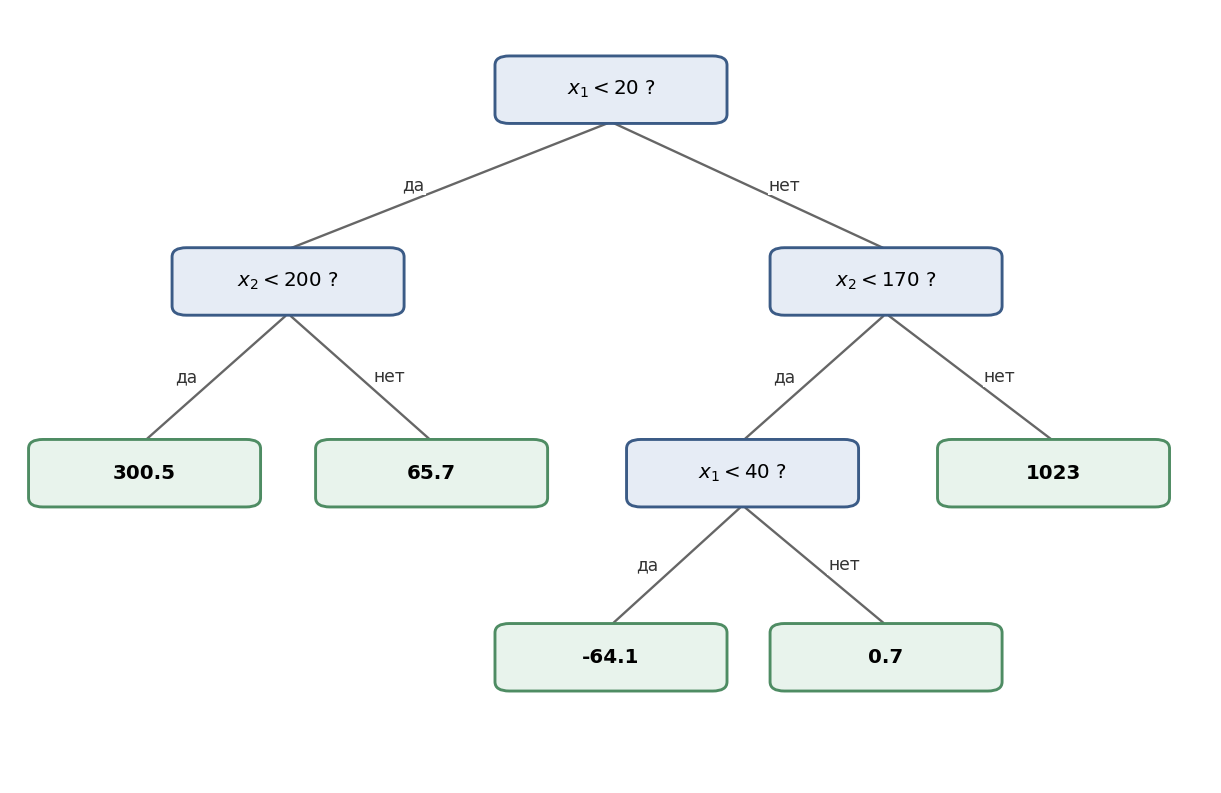


**Вопрос для размышления.** Возьмите вход, при котором функция возвращает $1023$, и опишите словами весь путь по дереву: какие условия и в каком порядке проверяются?

*Баллы: 6 за код, 4 за ответ на вопрос.*

In [3]:
# НАЧАЛО ВАШЕГО РЕШЕНИЯ

def get_prediction(x1, x2):
	if x1 < 20:
		if x2 < 200:
			return 300.5

		return 65.7

	if x2 < 170:
		if x1 < 40:
			return -64.1

		return .7
	
	return 1023

# КОНЕЦ ВАШЕГО РЕШЕНИЯ

In [4]:
# автотесты для самопроверки
assert get_prediction(15, 150) == 300.5
assert get_prediction(15, 350) == 65.7
assert get_prediction(35, 100) == -64.1
assert get_prediction(175, 100) == 0.7
assert get_prediction(175, 200) == 1023
print("Все тесты пройдены!")

Все тесты пройдены!


**Ваш ответ на вопрос для размышления:**

*(напишите здесь, 3-5 предложений)*

Поскольку, кажное сравнение не строгое можно взять x1 = 20 и x2 = 170.
```python
if 20 < 20 -> нет if 170 < 170 -> нет, значит 1023
assert get_prediction(20, 170) == 1023
```

### Задание 3. Сложение матриц (3 балла)

Матрицы (двумерные таблицы чисел) — основной формат данных в ML. Напишите функцию `matrix_sum(matrix1, matrix2)`, которая возвращает их поэлементную сумму.

Складывать можно только матрицы одинакового размера, поэтому сначала проверьте, что у матриц совпадает число строк и число столбцов в каждой строке. Если размеры не совпадают — выведите через `print()` сообщение `"Error! Matrices dimensions are different!"` и верните `None`.

Гарантируется, что на вход подаются прямоугольные матрицы (в каждой строке одинаковое число элементов).

**Пример:**
```python
a = [[1, 5, 4], [4, 2, -2], [7, 65, 88]]
matrix_sum(a, a)   # [[2, 10, 8], [8, 4, -4], [14, 130, 176]]
```

**Вопрос для размышления.** Допишите в ячейку с автотестами минимум 2 своих проверки на граничные случаи (например, матрица $1 \times 1$ или матрицы с разным числом столбцов) и в ответе поясните, что проверяет каждая. Почему размеры лучше проверить *до* вычислений, а не полагаться на то, что программа сама упадёт с ошибкой на несовпадении?

*Баллы: 2 за код, 1 за ответ на вопрос.*

In [5]:
matrix_example = [
    [1, 5, 4],
    [4, 2, -2],
    [7, 65, 88]
]

# НАЧАЛО ВАШЕГО РЕШЕНИЯ

def matrix_sum(matrix1, matrix2):
	if len(matrix1) != len(matrix2):
		print("Error! Matrices dimensions are different!")
		return None

	for i in range(len(matrix1)):
		if len(matrix1[i]) != len(matrix2[i]):
			print("Error! Matrices dimensions are different!")
			return None
 
	matrix3 = []
	for i in range(len(matrix1)):
		row = []
		for j in range(len(matrix1[i])):
			row += [matrix1[i][j] + matrix2[i][j]]
	
		matrix3 += [row]

	return matrix3

# КОНЕЦ ВАШЕГО РЕШЕНИЯ

In [6]:
# автотесты для самопроверки
assert matrix_sum(matrix_example, matrix_example) == [[2, 10, 8], [8, 4, -4], [14, 130, 176]]
assert matrix_sum([[1, 2]], [[1, 2], [3, 4]]) is None
assert matrix_sum([[1, 2, 3]], [[1, 2]]) is None
assert matrix_sum([[1]], [[2]]) == [[3]]
assert matrix_sum([[1, 2], [2, 3]], [[1, 2, 3], [2, 3, 4]]) is None
print("Все тесты пройдены!")

Error! Matrices dimensions are different!
Error! Matrices dimensions are different!
Error! Matrices dimensions are different!
Все тесты пройдены!


**Ваш ответ на вопрос для размышления:**

*(напишите здесь, 3-5 предложений)*

Сложение матриц размера 1 на 1
<div align="center">

$\begin{pmatrix} 1 \end{pmatrix} + \begin{pmatrix} 2 \end{pmatrix} = \begin{pmatrix} 3 \end{pmatrix}$
</div>

```python
assert matrix_sum([[1]], [[2]]) == [[3]]
```

Сложение матриц размера 2 на 2 и 3 на 3
<div align="center">

$\begin{pmatrix} 1 & 2 \\ 2 & 3 \end{pmatrix} + \begin{pmatrix} 1 & 2 & 3 \\ 2 & 3 & 4 \end{pmatrix} \Rightarrow $ Нельзя сложить из-за разного размера матриц
</div>

```python
assert matrix_sum([[1, 2], [2, 3]], [[1, 2, 3], [2, 3, 4]]) is None
```

Зачем же проверять размерность перед расчетами?

Стандартный ответ - это правила линейной алгебры, что мы можем складывать и перемножить только одинакового размера.

<p align="justify">Порассуждаем с точки зрения компьютерных наук. Нам подаются данные, и мы их обрабатываем. Пусть у нас есть сервис по линейной алгебре. Пользователь переходит в раздел "Матрицы" и использует функцию сложения. Начинаем процесс вычисления, выделяется память под новую матрицу и при вычисление элемента оказывается, что в строке у одной матрицы элементов больше, чем у другой и программа возвращает ошибку.

<p align="justify">Что осталось после? Выделенная память под матрицу, которую не посчитали или частично посчитана, ошибка и пользователь не понимаем, что он не так указал.

<p align="justify">Добавим к этому, что таких пользователей не 1, а 100, 1000 и т.д. - сервис просто упадет от нагрузки. Поэтому, сначала проверяем размерность, если не совпала, вернем сообщение, что размерности матрицы не совпадают. Иначе, дальше все рассчитывается без проблем, выделили память, отправили данные, освободили память. Ничего не виснет и работает в штатном режиме.

### Задание 4. Предобработка текста (3 балла)

Прежде чем скормить текст модели, его очищают. Напишите две функции.

**1. `get_words_list(text)`** — приводит текст к нижнему регистру, убирает знаки препинания и возвращает список слов. Внутри функции используйте локальный список знаков:
```python
punctuation_list = ['.', ',', ';', ':', '...', '!', '?', '-', '"', '(', ')']
```
Важно: в списке слов не должно оказаться пустых строк, даже если в тексте шли подряд несколько пробелов или знаков.

**2. `get_unique_words(words_list)`** — принимает список слов и возвращает отсортированный по алфавиту список *уникальных* слов.

**Пример:**
```python
text = "Arrakis, the planet known as Dune, is forever his place."
get_words_list(text)
# ['arrakis', 'the', 'planet', 'known', 'as', 'dune', 'is', 'forever', 'his', 'place']
```

**Вопрос для размышления.** Зависит ли результат `get_words_list` от порядка, в котором вы удаляете знаки из `punctuation_list` — почему да или почему нет?

*Баллы: 2 за код, 1 за ответ на вопрос.*

In [7]:
text_example = "Arrakis, the planet known as Dune, is forever his place."

# НАЧАЛО ВАШЕГО РЕШЕНИЯ

punctuation_list = ['.', ',', ';', ':', '...', '!', '?', '-', '"', '(', ')']

def get_words_list(text):
	text = text.lower()

	for s in punctuation_list:
		text = text.replace(s, "")

	return text.split() 


def get_unique_words(words_list):
	return sorted(set(words_list))

# КОНЕЦ ВАШЕГО РЕШЕНИЯ

In [8]:
# автотесты для самопроверки
assert get_words_list(text_example) == ['arrakis', 'the', 'planet', 'known', 'as', 'dune', 'is', 'forever', 'his', 'place']
assert get_words_list("A,  b.  C!") == ['a', 'b', 'c']   # несколько пробелов подряд -> без пустых строк
assert get_unique_words(['b', 'a', 'a', 'c', 'b']) == ['a', 'b', 'c']
assert get_unique_words([]) == []
print("Все тесты пройдены!")

Все тесты пройдены!


**Ваш ответ на вопрос для размышления:**

*(напишите здесь, 3-5 предложений)*

От порядка удаления знаков результат не зависит. 

Можно привести известный математический пример. Например $4 : 4 * 2$. <p align="justify">И всегда дают разные ответы, либо 4, либо 1/2. Все они по отдельности верны, но любой [***`математик скажет`***](https://www.youtube.com/shorts/ZF1FmiKlbgg), что самым верным ответом будет тот, как вы расставите скобки и тогда, если дать задачу распарсить пример со скобками, то нужно учитывать их начальное состояние, потому что, разделив не так и собрав обратно - результат будет иным. С точки зрения текста, как мы можем наблюдать за LLM, при делении на токены, тут абсолютно не важно, есть там знаки или нет. Пользователь, читающий какой-либо контент, сам задает тон. 

Да, может знаки и задают эмоции и т.п. с точки зрения литературы, но при обработке это не на что не влияет. Это можно наблюдать в технологиях [***`TF-IDF`***](https://en.wikipedia.org/wiki/Tf%E2%80%93idf), [***`BM25`***](https://en.wikipedia.org/wiki/Okapi_BM25).

---

## Часть 2. Объектно-ориентированное программирование

В первой части мы работали с данными через отдельные переменные и функции. Но когда у сущности есть и свои данные, и своё поведение - удобнее описать её классом. В этой части вы соберёте маленький проект про доставку еды: опишете блюдо, сделаете его виды через наследование и соберёте из блюд заказ. Каждое задание опирается на предыдущее, поэтому выполняйте их по порядку.


### Задание 5. Класс Dish (3 балла)

Реализуйте класс Dish, который описывает блюдо.

Конструктор __init__ принимает три параметра и сохраняет их в обычные атрибуты:
- name (строка) - название, атрибут name;
- price (число) - цена, атрибут price;
- is_vegan (True или False) - веганское ли блюдо, атрибут is_vegan.

Добавьте два обычных метода:
- get_info() - возвращает строку вида "Салат, 250 руб.";
- is_vegan_dish() - возвращает True, если блюдо веганское, иначе False.


In [9]:
class Dish:
	# НАЧАЛО ВАШЕГО РЕШЕНИЯ
	def __init__(self, name, price, is_vegan):
		self.name = name
		self.price = price
		self.is_vegan = is_vegan


	def get_info(self):
		return f"{self.name}, {self.price} руб."


	def is_vegan_dish(self):
		return self.is_vegan

	# КОНЕЦ ВАШЕГО РЕШЕНИЯ

In [10]:
# автотесты для самопроверки
d = Dish("Салат", 250, True)
assert d.name == "Салат"
assert d.price == 250
assert d.is_vegan == True
assert d.get_info() == "Салат, 250 руб."
assert d.is_vegan_dish() == True
assert Dish("Стейк", 750, False).is_vegan_dish() == False
print("Все тесты пройдены!")

Все тесты пройдены!


**Ваш ответ на вопрос для размышления:**

*(напишите здесь, 3-5 предложений)*

Для данного задания не было вопроса для размышления

### Задание 6. Наследование: HotDish и ColdDish (3 балла)

Создайте два класса-наследника класса Dish - HotDish (горячее блюдо) и ColdDish (холодное блюдо).

HotDish:
- в конструкторе принимает те же name, price, is_vegan и передаёт их в конструктор Dish через super().__init__(...);
- дополнительно задаёт атрибут temperature со значением "горячее";
- переопределяет метод get_info(), возвращая строку вида "Борщ, 150 руб., горячее".

ColdDish:
- устроен так же, но атрибут temperature равен "холодное";
- метод get_info() возвращает строку вида "Мороженое, 100 руб., холодное".

Обратите внимание: name, price, is_vegan и метод is_vegan_dish() наследникам не нужно писать заново - они достаются от Dish.

In [11]:
class HotDish(Dish):
	# НАЧАЛО ВАШЕГО РЕШЕНИЯ
	temperature = "горячее"

	def __init__(self, name, price, is_vegan):
		super().__init__(name, price, is_vegan)


	def get_info(self):
		return f"{self.name}, {self.price} руб., {self.temperature}"
	# КОНЕЦ ВАШЕГО РЕШЕНИЯ


class ColdDish(Dish):
	# НАЧАЛО ВАШЕГО РЕШЕНИЯ
	temperature = "холодное"

	def __init__(self, name, price, is_vegan):
		super().__init__(name, price, is_vegan)


	def get_info(self):
		return f"{self.name}, {self.price} руб., {self.temperature}"
	# КОНЕЦ ВАШЕГО РЕШЕНИЯ

In [12]:
# автотесты для самопроверки
h = HotDish("Борщ", 150, False)
assert h.name == "Борщ"
assert h.price == 150
assert h.temperature == "горячее"
assert h.get_info() == "Борщ, 150 руб., горячее"
assert h.is_vegan_dish() == False   # метод достался от Dish

c = ColdDish("Мороженое", 100, True)
assert c.temperature == "холодное"
assert c.get_info() == "Мороженое, 100 руб., холодное"
assert c.is_vegan_dish() == True
print("Все тесты пройдены!")

Все тесты пройдены!


**Ваш ответ на вопрос для размышления:**

*(напишите здесь, 3-5 предложений)*

Для данного задания не было вопроса для размышления

### Задание 7. Класс Order (3 балла)

Теперь соберём из блюд заказ. Реализуйте класс Order.

Конструктор __init__ принимает имя клиента customer_name, сохраняет его в атрибут customer_name и создаёт пустой список блюд - атрибут dishes.

Добавьте три обычных метода:
- add_dish(dish) - добавляет переданное блюдо (объект Dish или его наследника HotDish/ColdDish) в список dishes;
- total_price() - возвращает сумму цен всех блюд заказа;
- dish_count() - возвращает количество блюд в заказе.

In [13]:
class Order:
	# НАЧАЛО ВАШЕГО РЕШЕНИЯ
	def __init__(self, customer_name):
		self.customer_name = customer_name
		self.dishes = []


	def add_dish(self, dish):
		self.dishes += [dish]


	def total_price(self):
		return sum(dish.price for dish in self.dishes)


	def dish_count(self):
		return len(self.dishes)
	# КОНЕЦ ВАШЕГО РЕШЕНИЯ

In [14]:
# автотесты для самопроверки
order = Order("Иван")
assert order.customer_name == "Иван"
assert order.dishes == []
assert order.dish_count() == 0

order.add_dish(Dish("Салат", 250, True))
order.add_dish(HotDish("Борщ", 150, False))
order.add_dish(ColdDish("Мороженое", 100, True))

assert order.dish_count() == 3
assert order.total_price() == 500
print("Все тесты пройдены!")

Все тесты пройдены!


---

На этом всё. Не забудьте перезапустить ноутбук сверху вниз перед сдачей и ответить на все вопросы для размышления **своими словами**:)

**Успехов!**